In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [2]:
df = pd.read_csv('nity18442004.csv')
print(df.shape)
df.head()

(161, 1)


,x
0,8.5
1,8.3
2,9.7
3,8.9
4,8.5


In [3]:
from datetime import datetime
import calendar
dates = []

for year in range(1844, 2005):
    month = 12
    last_day = calendar.monthrange(year, month)[1]
    date = f"{year}-{month}-{last_day}"
    dates.append(date)


In [4]:
df['Date'] = dates
df['Date'] = pd.to_datetime(df['Date'])
df.set_index('Date',inplace= True)

In [5]:
df

,x
Date,
1844-12-31,8.5
1845-12-31,8.3
1846-12-31,9.7
1847-12-31,8.9
1848-12-31,8.5
...,...
2000-12-31,9.2
2001-12-31,8.8
2002-12-31,9.5


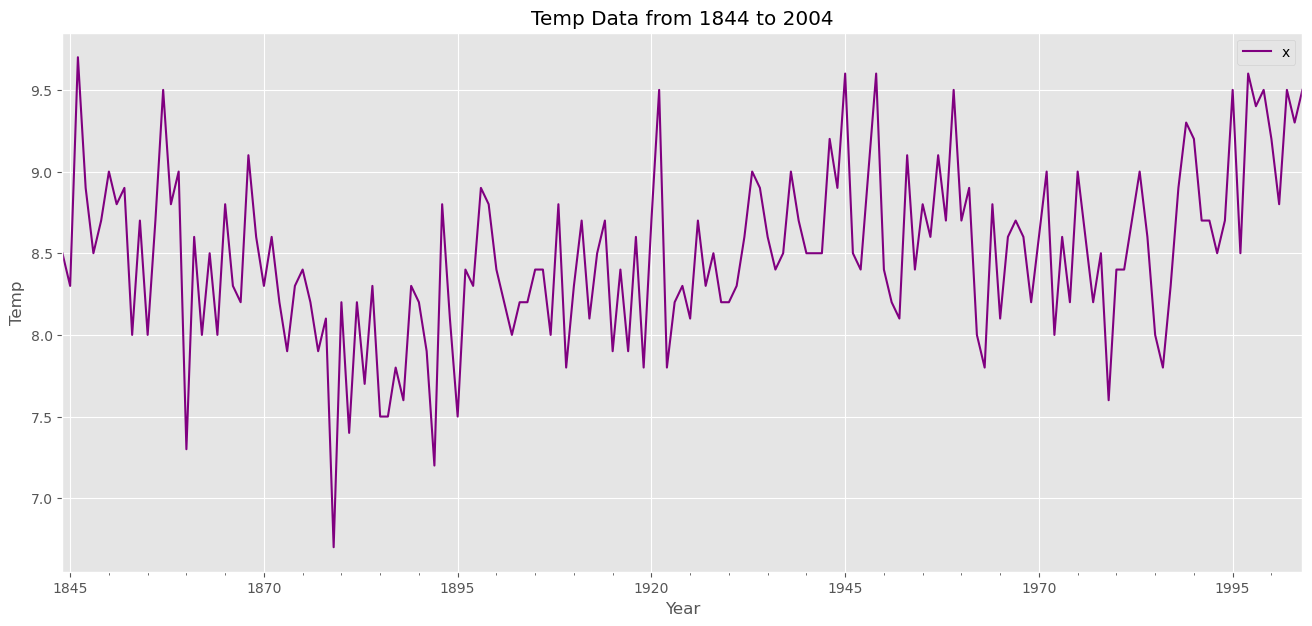

In [6]:
plt.style.use('default')
plt.style.use('ggplot')

a = '1844-1-31'
b = '2004-12-31'

df.loc[a:b].plot(figsize=(16, 7), color='purple')
plt.title('Temp Data from 1844 to 2004')
plt.xlabel('Year')
plt.ylabel('Temp')
plt.show()

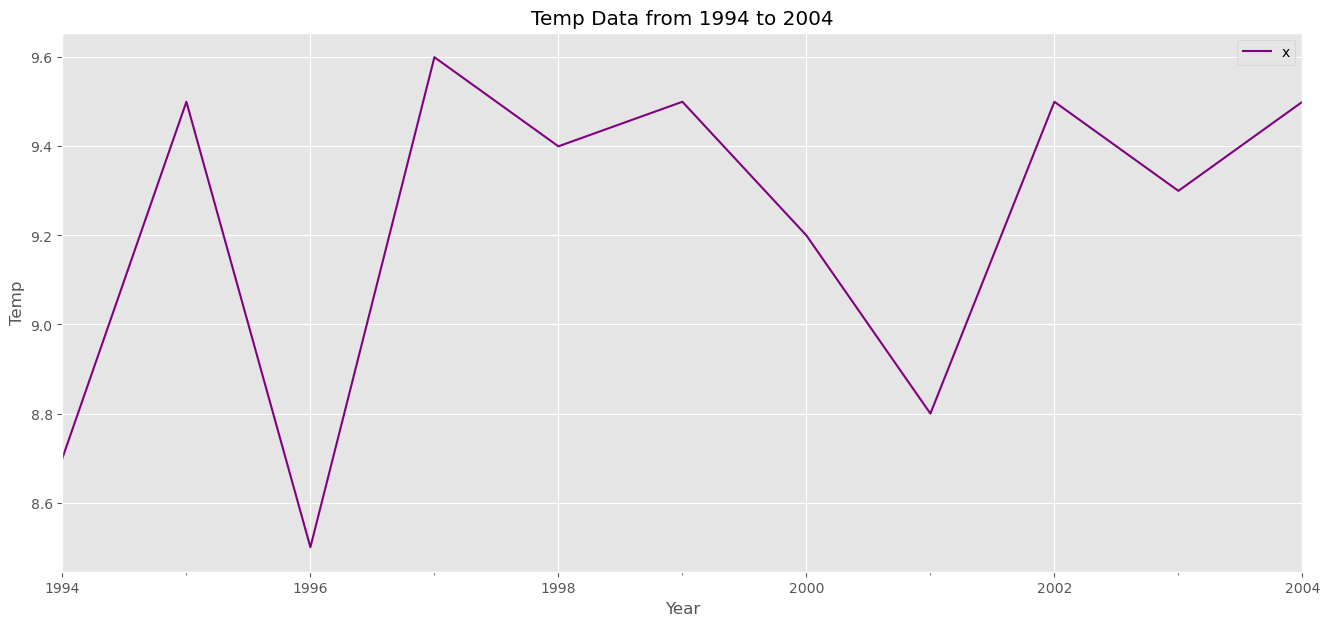

In [8]:
plt.style.use('default')
plt.style.use('ggplot')

a = '1994-12-31'
b = '2004-12-31'

df.loc[a:b].plot(figsize=(16, 7), color='purple')
plt.title('Temp Data from 1994 to 2004')
plt.xlabel('Year')
plt.ylabel('Temp')
plt.show()

In [9]:
# Check the stationarity of the time series using the Augmented Dickey-Fuller (ADF) test
from statsmodels.tsa.stattools import adfuller
result = adfuller(df['x'])
print(f'ADF Statistic: {result[0]}')
print(f'p-value: {result[1]}')
print('Critical Values:')
for key, value in result[4].items():
    print(f'   {key}: {value}')

ADF Statistic: -1.352375658748819
p-value: 0.6048831174332495
Critical Values:
   1%: -3.473542528196209
   5%: -2.880497674144038
   10%: -2.576878053634677


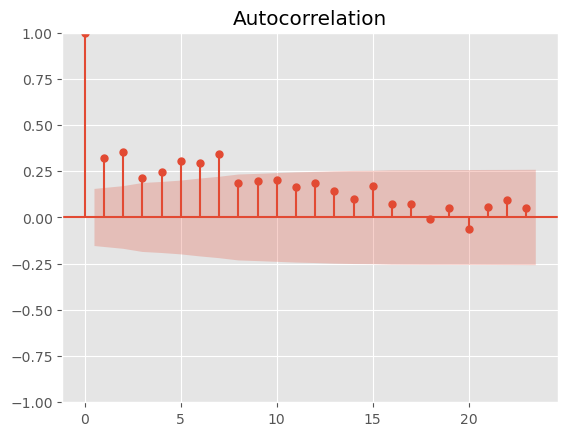

In [10]:
from statsmodels.graphics.tsaplots import plot_acf
# Plot the ACF
plot_acf(df['x'])
plt.show()

C:\Users\Lenovo\anaconda3\lib\site-packages\statsmodels\graphics\tsaplots.py:348: FutureWarning: The default method 'yw' can produce PACF values outside of the [-1,1] interval. After 0.13, the default will change tounadjusted Yule-Walker ('ywm'). You can use this method now by setting method='ywm'.
  warnings.warn(


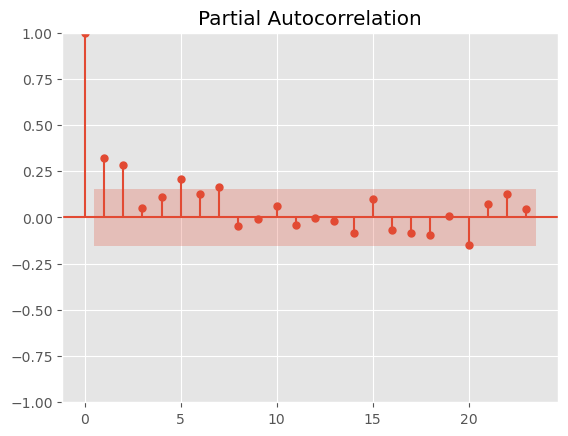

In [11]:
from statsmodels.graphics.tsaplots import plot_pacf
# Plot the ACF
plot_pacf(df['x'])
plt.show()

In [12]:
from sklearn.model_selection import train_test_split

# split the dataset into training and test sets
train_data, test_data = train_test_split(df, test_size=10, shuffle=False)


C:\Users\Lenovo\anaconda3\lib\site-packages\statsmodels\tsa\base\tsa_model.py:471: ValueWarning: No frequency information was provided, so inferred frequency A-DEC will be used.
  self._init_dates(dates, freq)
C:\Users\Lenovo\anaconda3\lib\site-packages\statsmodels\tsa\base\tsa_model.py:471: ValueWarning: No frequency information was provided, so inferred frequency A-DEC will be used.
  self._init_dates(dates, freq)
C:\Users\Lenovo\anaconda3\lib\site-packages\statsmodels\tsa\base\tsa_model.py:471: ValueWarning: No frequency information was provided, so inferred frequency A-DEC will be used.
  self._init_dates(dates, freq)
C:\Users\Lenovo\anaconda3\lib\site-packages\statsmodels\tsa\statespace\sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'


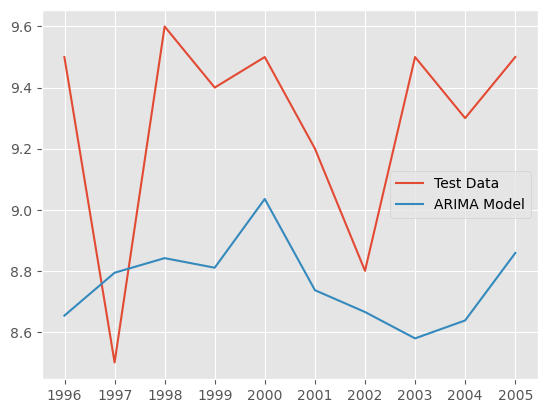

In [13]:
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_squared_error, mean_absolute_error
# Fit an ARIMA model to the training set
model = ARIMA(train_data['x'], order=(22, 1, 1))
results = model.fit()

# Make predictions on the testing set
predictions = results.predict(start=test_data.index[0], end=test_data.index[-1], typ='levels')

# Plot the results
#plt.plot(train_data['x'], label='Training Data')
plt.plot(test_data['x'], label='Test Data')
plt.plot(predictions, label='ARIMA Model')
plt.legend()
plt.show()

In [14]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing



# Fit the exponential smoothing model to the training data
model = ExponentialSmoothing(train_data['x'],  seasonal_periods=12, trend='add', seasonal='add').fit()

# Make predictions for the test set
predictions = model.predict(start=test_data.index[0], end=test_data.index[-1])

# Calculate the error metrics
mse = ((predictions - test_data['x']) ** 2).mean()
rmse = np.sqrt(mse)
mae = (abs(predictions - test_data['x'])).mean()

# Print the error metrics
print('MSE: ', mse)
print('RMSE: ', rmse)
print('MAE: ', mae)

C:\Users\Lenovo\anaconda3\lib\site-packages\statsmodels\tsa\base\tsa_model.py:471: ValueWarning: No frequency information was provided, so inferred frequency A-DEC will be used.
  self._init_dates(dates, freq)


MSE:  0.5571074613282722
RMSE:  0.7463963165291427
MAE:  0.6692699167466627


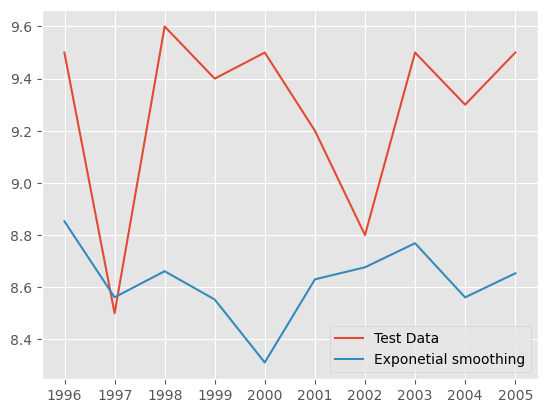

In [14]:
plt.plot(test_data['x'], label='Test Data')
plt.plot(predictions, label='Exponetial smoothing')
plt.legend()
plt.show()


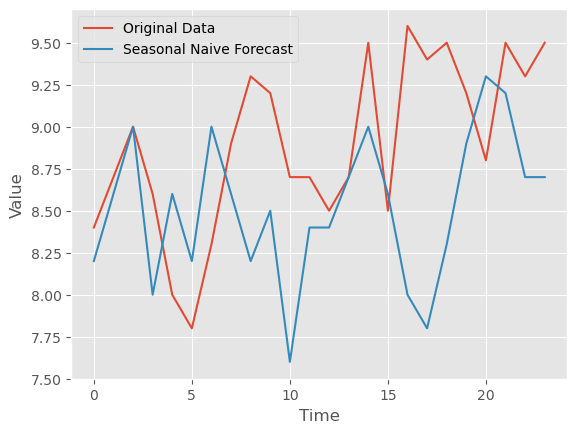

In [15]:
def seasonal_naive_forecast(data, seasonal_period):
    forecast = np.roll(data, seasonal_period)
    return forecast

# Example usage:
# Assuming 'data' is your time series data and 'seasonal_period' is the length of the seasonal pattern

# Provide your actual time series data here
data = df['x']
# Specify the length of the seasonal pattern
seasonal_period = 12

# Generate the seasonal naive forecast
forecast = seasonal_naive_forecast(data, seasonal_period)

# Plot the last 24 points of the original data and the forecast
last_24_data = data[-24:]
last_24_forecast = forecast[-24:]

plt.plot(range(len(last_24_data)), last_24_data, label='Original Data')
plt.plot(range(len(last_24_forecast)), last_24_forecast, label='Seasonal Naive Forecast')
plt.xlabel('Time')
plt.ylabel('Value')
plt.legend()
plt.show()
